# Hands-on 24 (Bab 10): Forecasting Suhu Ruang

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 10.

Memprediksi suhu 1 langkah ke depan (10 menit): baseline last value dan moving
average dibandingkan dengan Linear Regression berbasis lag. Split time-aware 70/15/15.

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Siapkan Dataset Forecasting

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/prepare_room_forecast_dataset.py"], capture_output=True, text=True)
print(r.stdout)

[SUKSES] Dataset forecasting suhu siap digunakan.
Train: 3019, Validation: 647, Test: 647
File disimpan di: data/processed/forecast_room



## 2. Baseline (Last Value & Moving Average)

In [3]:
r = subprocess.run([sys.executable, "scripts/baseline_room_forecast.py"], capture_output=True, text=True)
print(r.stdout)

=== Baseline Last Value ===
MAE : 0.3897836166924265
RMSE: 0.49239235558572403

=== Baseline Moving Average ===
MAE : 0.37055126223596074
RMSE: 0.45809092460848344

[SUKSES] Hasil baseline disimpan ke: data/processed/forecast_room/baseline_predictions.csv



## 3. Linear Regression Berbasis Lag

In [4]:
r = subprocess.run([sys.executable, "scripts/linear_regression_room_forecast.py"], capture_output=True, text=True)
print(r.stdout)

=== Linear Regression - Validation ===
MAE : 0.2985088592898283
RMSE: 0.36855575536971347

=== Linear Regression - Test ===
MAE : 0.3014574195582235
RMSE: 0.38996679318456706

[SUKSES] Prediksi disimpan ke: data/processed/forecast_room/linear_predictions.csv



## 4. Visualisasi Perbandingan

[SUKSES] outputs/figures/room_forecast_compare.png



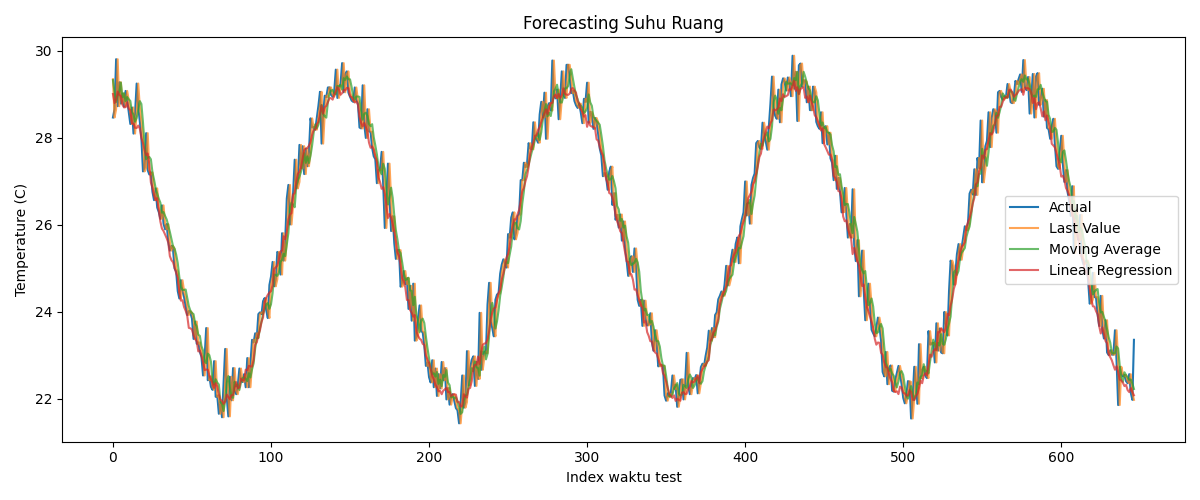

In [5]:
r = subprocess.run([sys.executable, "scripts/plot_room_forecast_comparison.py"], capture_output=True, text=True)
print(r.stdout)
from IPython.display import Image
Image("outputs/figures/room_forecast_compare.png")

## Penutup

Baseline memang kuat (MAE sekitar 0.37-0.39 C), tetapi Linear Regression berbasis lag
mengalahkannya di test (MAE sekitar 0.30 C, RMSE 0.39 C). Model memberi nilai tambah
nyata di atas baseline jujur. Dataset di `data/processed/forecast_room/`, visualisasi di
`outputs/figures/room_forecast_compare.png`.